# Simple Solutions to the Inverse Problem

This notebook implements the simple inverse problem solution described in Rodgers 2000. This is the case where the influence of clouds and other absorbers can be safely ignored, such that the radiative transfer equation decomposes to:

$$
L(\nu) = \int^{\infty}_{0}B[\nu, T(z)]\frac{d\tau(\nu,z)}{dz}dz
$$

Where $B[\nu, T(z)]$ is the Planck function, calculating radiance as a function of temperature. For the sake of simplicity in this example, ground emission is zero, its just atmospheric contributions. Secondly, consider taking measurements at a close spectral interval such that the wavenumber variability of radiance can be ignored (ie, we just fix the wavenumber). This reduces the problem further to:

$$
L(\nu_i) = \int^{\infty}_{0}B[\bar{\nu}, T(z)]K_i(z)dz
$$

where $K_i(z) = \frac{d\tau(\bar{\nu}, z)}{dz}$. The equation is now linear in $B[T(z)]$ which is our unknown we'd want to recover. Fundamentally, we can conclude that if $B[T(z)]$ is found, we can recover the profile of temperature. 

Solving the equation above is clearly going to be a challenge. Not least of which is the fact that there are a finite number of measurements to solve a continuous unknown (the problem is ill-posed). We therefore deconstruct the continuous $B[\bar{\nu}, T(z)]$ to a basis, using polynomial, sin, cos, whatever you'd like (although polynomial tends to be the best suited).

$$
B(\bar{\nu}, T(z)) = \sum_{j=1}^{m}w_jW_j(z)
$$

Substituting back into the equation of interest we get:
$$
L_i = \sum_{j=1}^{m}w_j \int_{0}^{\infty}W_j(z)K_i(z)dz = \sum_{j=1}^{m}C_{ij}w_j
$$

Defining the matrix C as $C_{ij}=\int_{0}^{\infty}W_j(z)K_i(z)dz$, which can be easily calculated. It thus follows that we have a set of m equations with m unkowns, the problem can be solved. It then also follows that:

$$
B(\bar{\nu}, T(z)) = \sum_{i,j}W_j(z)C^{-1}_{ji}L_i
$$

Unfortunately, this problem set-up tends to be terribly ill-conditioned in many (most) practical applications. Consequently any error or uncertainty will be monumentally amplified and the solution will be meaningless. Perhaps thankfully so, otherwise the rest of the book would be unneeded. 

In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt

from pyrodgers.forward import ForwardModel
from pyrodgers.inversion import Inversion

Create a true profile of temperatures that we will be trying to recover using the inversion method discussed. This is of course a synthetic case, but broadly reflective of a true atmospheric profile. 

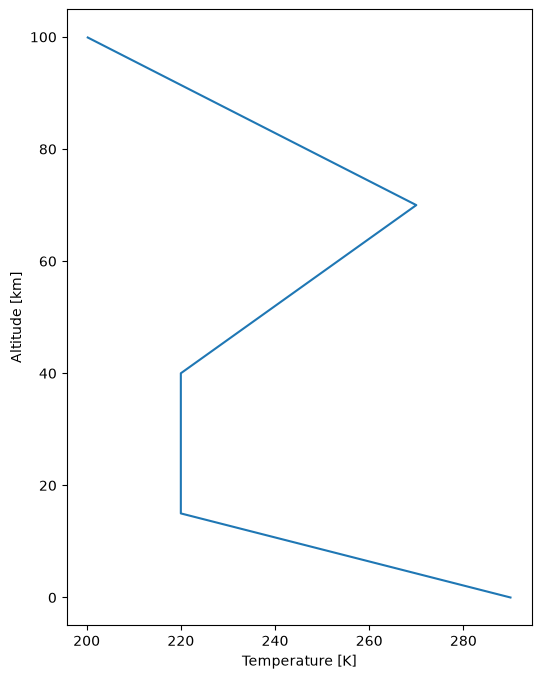

In [23]:
altitude = np.arange(0, 100, 0.1, dtype=float)
temperature = np.empty_like(altitude)

mask = (altitude >= 0) & (altitude < 15)
temperature[mask] = (
    290 - (290 - 220) / 15 * altitude[mask]
)

mask = (altitude >= 15) & (altitude < 40)
temperature[mask] = 220

mask = (altitude >= 40) & (altitude < 70)
temperature[mask] = (
    220 + (270 - 220) / 30 * (altitude[mask] - 40)
)

mask = altitude >= 70
temperature[mask] = (
    270 - (270 - 200) / 30 * (altitude[mask] - 70)
)

plt.figure(figsize=(6, 8))
plt.plot(temperature, altitude)
plt.xlabel("Temperature [K]")
plt.ylabel("Altitude [km]")
plt.show()

Create a set of synthetic weighting functions, representing a typical nadir sounder measuring thermal emission. This too is entirely synthetic, and would usually be informed by the forward model and prior knowledge of the sensor etc. For now, we just make them up to be distributions like so:

[10 15 20 25 30 35 40 45 50 55 60 65 70 75]
(14, 1000)


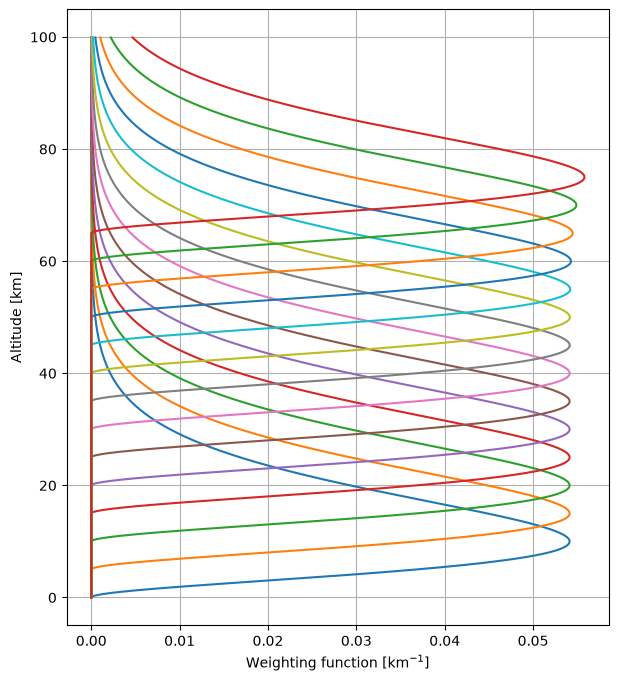

In [24]:
centers = np.arange(10,80,5)
print(centers)

n = 2
theta = 5.0

weighting_functions = []

for center in centers:

    x = altitude - (center - n * theta)

    K = np.zeros_like(altitude)
    mask = x >= 0
    K[mask] = x[mask]**n * np.exp(-x[mask] / theta)

    K /= np.trapezoid(K, altitude)
    weighting_functions.append(K)

weighting_functions = np.array(weighting_functions)
print(weighting_functions.shape)

plt.figure(figsize=(7, 8))

for center, K in zip(centers, weighting_functions):
    plt.plot(K, altitude, label=f'{center} km')

plt.xlabel('Weighting function [km$^{-1}$]')
plt.ylabel('Altitude [km]')
plt.grid()
plt.show()

Notice the lack of observations at high altitudes, and at very low altitudes, this will cascade into error for these regions. 

Use the temeprature profile to simulate the radiances at the weighting function levels. Note that this is done with no uncertainty, even then the retrieval is a bit off. If you implement additional uncertainty here, the problem breaks entirely due to the ill-conditioning. 

In [4]:
wavelength = 10e-6

model = ForwardModel(temperature, altitude, wavelength)
L = model.simulate_radiance(weighting_functions)


Construct C following the discussion above, using the basis functions and the weighting functions. 

In [10]:
model_inv = Inversion(altitude, wavelength, weighting_functions)
model_inv.basis_functions(basis_type="polynomial")
model_inv.construct_C()

Reconstruct the signal using the methods discussed above

In [6]:
B_reconstructed = model_inv.reconstruct_signal(L)

temp_reconstructed = model.inverse_planck_function(B_reconstructed)

/Users/mfranssen/Documents/stuff/PyRodgers/src/pyrodgers/forward.py:40: RuntimeWarning: invalid value encountered in log1p
  * np.log1p(exponent)


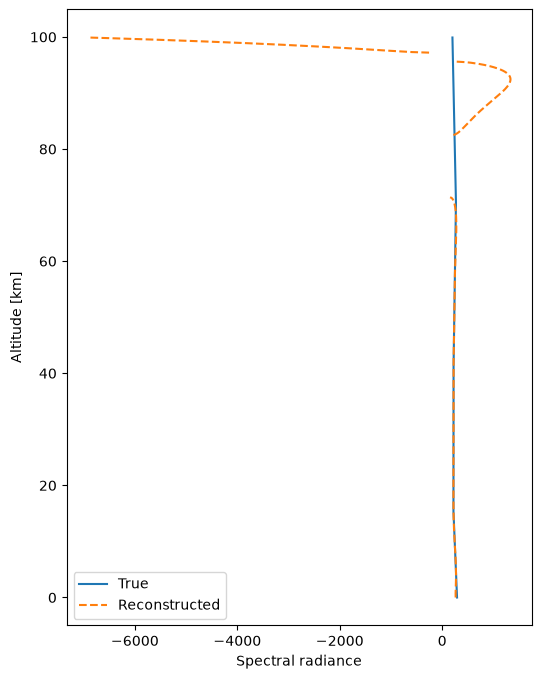

In [7]:
plt.figure(figsize=(6, 8))

plt.plot(temperature, altitude, label="True")
plt.plot(temp_reconstructed, altitude, "--", label="Reconstructed")

plt.xlabel("Spectral radiance")
plt.ylabel("Altitude [km]")
plt.legend()
plt.show()

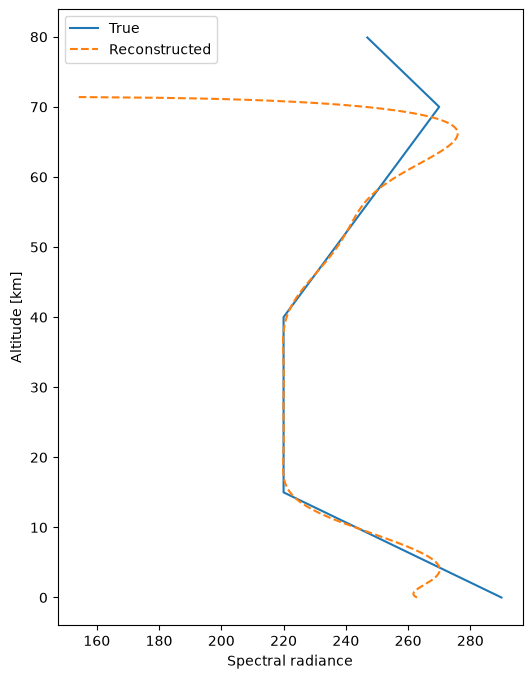

In [8]:
plt.figure(figsize=(6, 8))

plt.plot(temperature[:800], altitude[:800], label="True")
plt.plot(temp_reconstructed[:800], altitude[:800], "--", label="Reconstructed")

plt.xlabel("Spectral radiance")
plt.ylabel("Altitude [km]")
plt.legend()
plt.savefig(os.getcwd() + '/data/reconstructed_profile.png')
plt.show()

In [11]:
np.linalg.cond(model_inv.C)

np.float64(18017024692300.22)

The retrieved profile works generally well, but keep in mind this is without any measurement error. The ill-conditioned nature of the problem (observe above) makes this a very finnicky method. Of course, there are things we can do about this, all these will be discussed later. 